# Requirement Setup

In [1]:
!pip install prophet
!pip install scikit-learn
!pip install tensorflow
!pip install setuptools
!pip install keras-tuner


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
from prophet import Prophet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
import keras_tuner as kt
import numpy as np
import time
import matplotlib.pyplot as plt
from datetime import datetime
from prophet.serialize import model_to_json, model_from_json

C:\Users\sofia\.codex\.chatgpt-projects\g-p-67a332acf1fc8191bddbeac79c7b1526\research-reproduction\environments\forecast-venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Importing plotly failed. Interactive plots will not work.


Enable / Disable Hyperparameter Tuning

In [3]:
HYPERPARAMETER_TUNING = False

In [4]:
np.random.seed(42)
tf.random.set_seed(42)

# Data Loading

In [5]:
df_nasa = pd.read_csv('datasets/nasa.csv')
df_nasa.columns = ['ds', 'y']
df_nasa['ds'] = pd.to_datetime(df_nasa['ds'])

print(f'NASA DATASET - Dates: {df_nasa["ds"].count()} | Total: {df_nasa["y"].sum()}')
df_nasa.head()

NASA DATASET - Dates: 81396 | Total: 3461612


,ds,y
0,1995-07-01 00:00:00,42
1,1995-07-01 00:01:00,61
2,1995-07-01 00:02:00,57
3,1995-07-01 00:03:00,71
4,1995-07-01 00:04:00,70


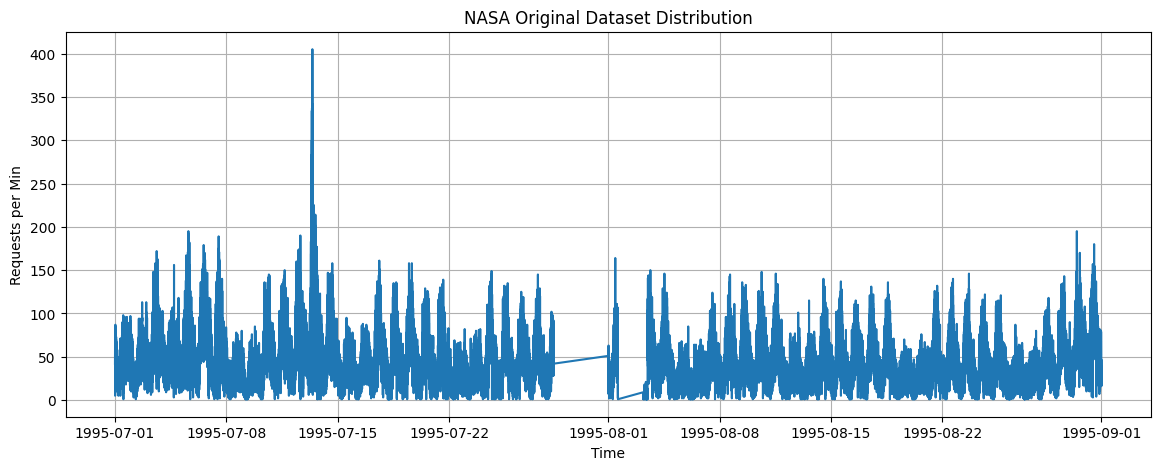

In [6]:
plt.figure(figsize=(14, 5))
plt.plot(df_nasa['ds'], df_nasa['y'])
plt.title('NASA Original Dataset Distribution')
plt.xlabel('Time')
plt.ylabel('Requests per Min')
plt.grid(True)
plt.savefig("images/nasa-original.jpeg", dpi=300, bbox_inches='tight', pad_inches=0)
plt.show()

# Data Splitting & Preprocessing

1.   Split datasets as 70% training, 30% testing
2.   Fill for empty data
3.   Drop duplicate data

In [7]:
train_df_nasa, test_df_nasa = train_test_split(df_nasa, test_size=0.3, random_state=42, shuffle=False)

print(f'NASA DATASET: Train Set: {train_df_nasa.shape} | Test Set: {test_df_nasa.shape}')

NASA DATASET: Train Set: (56977, 2) | Test Set: (24419, 2)


In [8]:
train_df_nasa['y'].fillna(method='ffill', inplace=True)
train_df_nasa.drop_duplicates(subset='ds', inplace=True)

print(f'NASA DATASET: Train Set: {train_df_nasa.shape} | Test Set: {test_df_nasa.shape}')

NASA DATASET: Train Set: (56977, 2) | Test Set: (24419, 2)


C:\Users\sofia\AppData\Local\Temp\ipykernel_10552\2063219103.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train_df_nasa['y'].fillna(method='ffill', inplace=True)
C:\Users\sofia\AppData\Local\Temp\ipykernel_10552\2063219103.py:1: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  train_df_nasa['y'].fillna(method='ffill', inplace=True)


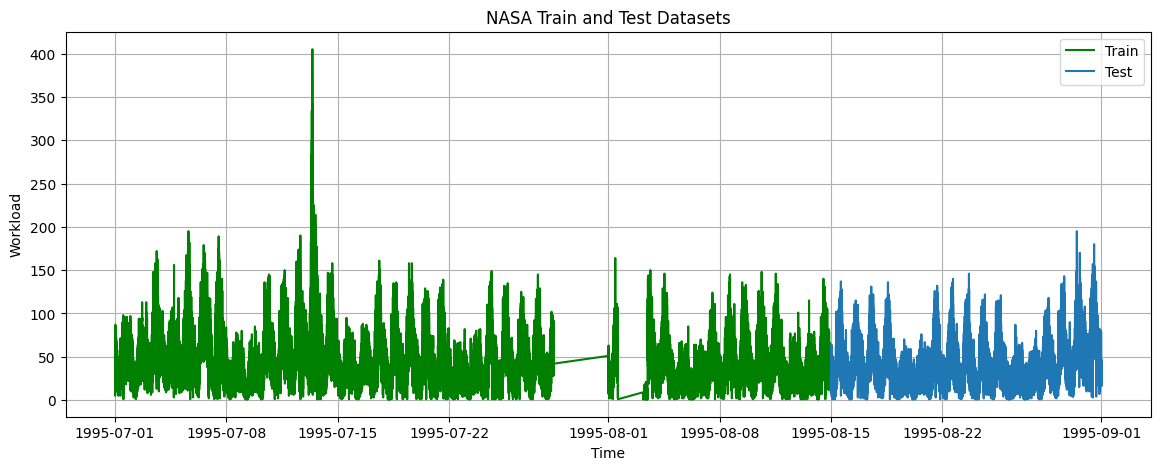

In [9]:
plt.figure(figsize=(14, 5))
plt.plot(train_df_nasa['ds'], train_df_nasa['y'], label='Train', color='green')
plt.plot(test_df_nasa['ds'], test_df_nasa['y'], label='Test', color='#1f77b4')
plt.title('NASA Train and Test Datasets')
plt.xlabel('Time')
plt.ylabel('Workload')
plt.grid(True)
plt.legend()
plt.savefig("images/nasa-train-test.jpeg", dpi=300, bbox_inches='tight', pad_inches=0)
plt.show()

# Model Training

## Seasonality Capturing with Prophet

### Train Model

In [10]:
model_one = Prophet(
    growth='linear',
    changepoint_prior_scale=5.1,
    yearly_seasonality=False,
    weekly_seasonality=20,
    daily_seasonality=50,
    seasonality_prior_scale=30
)
model_one.fit(train_df_nasa)

15:32:01 - cmdstanpy - INFO - Chain [1] start processing


15:33:47 - cmdstanpy - INFO - Chain [1] done processing


### Predict Dataset

In [11]:
forecast_train_df_nasa = model_one.predict(train_df_nasa[['ds']].copy())

start_time = time.time()
forecast_test_df_nasa = model_one.predict(test_df_nasa[['ds']].copy())
end_time = time.time()

In [12]:
forecast_test_df_nasa_analysis = test_df_nasa.copy()
forecast_test_df_nasa_analysis = forecast_test_df_nasa_analysis.merge(forecast_test_df_nasa[['ds', 'yhat']], on='ds', how='left')

mse = mean_squared_error(forecast_test_df_nasa_analysis['y'], forecast_test_df_nasa_analysis['yhat'])
rmse = np.sqrt(mse)
mae = mean_absolute_error(forecast_test_df_nasa_analysis['y'], forecast_test_df_nasa_analysis['yhat'])
r2 = r2_score(forecast_test_df_nasa_analysis['y'], forecast_test_df_nasa_analysis['yhat'])
model_one_time = (end_time - start_time) * 1000

print('=== Facebook Prophet Model Metrics ===')
print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'MAE: {mae}')
print(f'R²: {r2}')
print(f'Prediction Time: {model_one_time}ms')

=== Facebook Prophet Model Metrics ===
MSE: 269.0361723036441
RMSE: 16.402322161927074
MAE: 12.573171077770498
R²: 0.5791560799975353
Prediction Time: 4286.123037338257ms


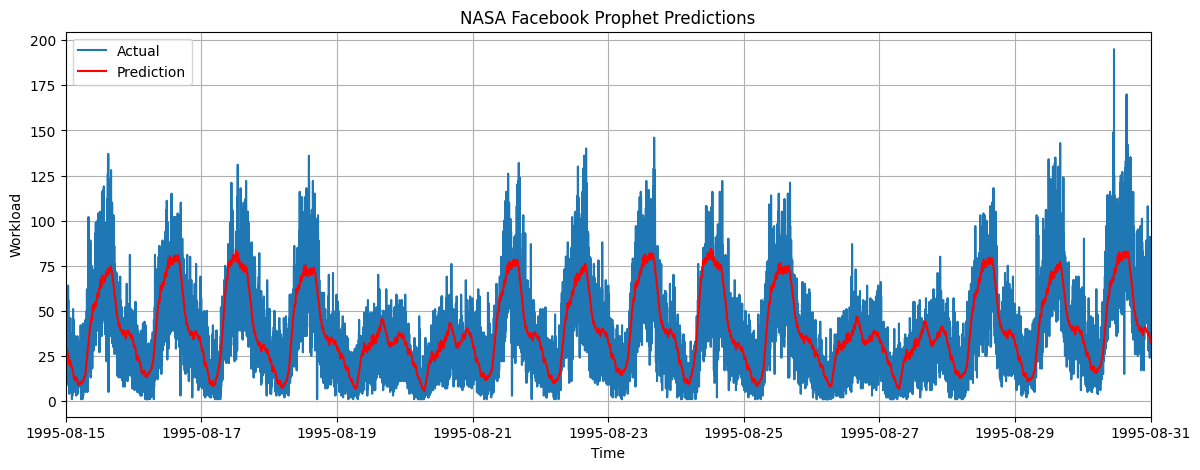

In [13]:
plt.figure(figsize=(14, 5))
# plt.plot(train_df_nasa['ds'], train_df_nasa['y'], label='Train', color='green')
plt.plot(test_df_nasa['ds'], test_df_nasa['y'], label='Actual', color='#1f77b4')
plt.plot(forecast_test_df_nasa['ds'], forecast_test_df_nasa['yhat'], label='Prediction', color='red')
plt.title('NASA Facebook Prophet Predictions')
plt.xlim(pd.to_datetime('1995-08-15'), pd.to_datetime('1995-08-31'))
plt.xlabel('Time')
plt.ylabel('Workload')
plt.grid(True)
plt.legend()
plt.savefig("images/nasa-prophet-output.jpeg", dpi=300, bbox_inches='tight', pad_inches=0)
plt.show()

C:\Users\sofia\.codex\.chatgpt-projects\g-p-67a332acf1fc8191bddbeac79c7b1526\research-reproduction\environments\forecast-venv\Lib\site-packages\prophet\plot.py:228: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  fcst_t = fcst['ds'].dt.to_pydatetime()
C:\Users\sofia\.codex\.chatgpt-projects\g-p-67a332acf1fc8191bddbeac79c7b1526\research-reproduction\environments\forecast-venv\Lib\site-packages\prophet\plot.py:397: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  artists += ax.plot(df_y['ds'].dt.to_pydatetime(), seas[name], ls='-',
C:\Users\sofia\.codex\.chatgpt-projects\g-p-67a332acf1fc8191bddbeac79c7b152

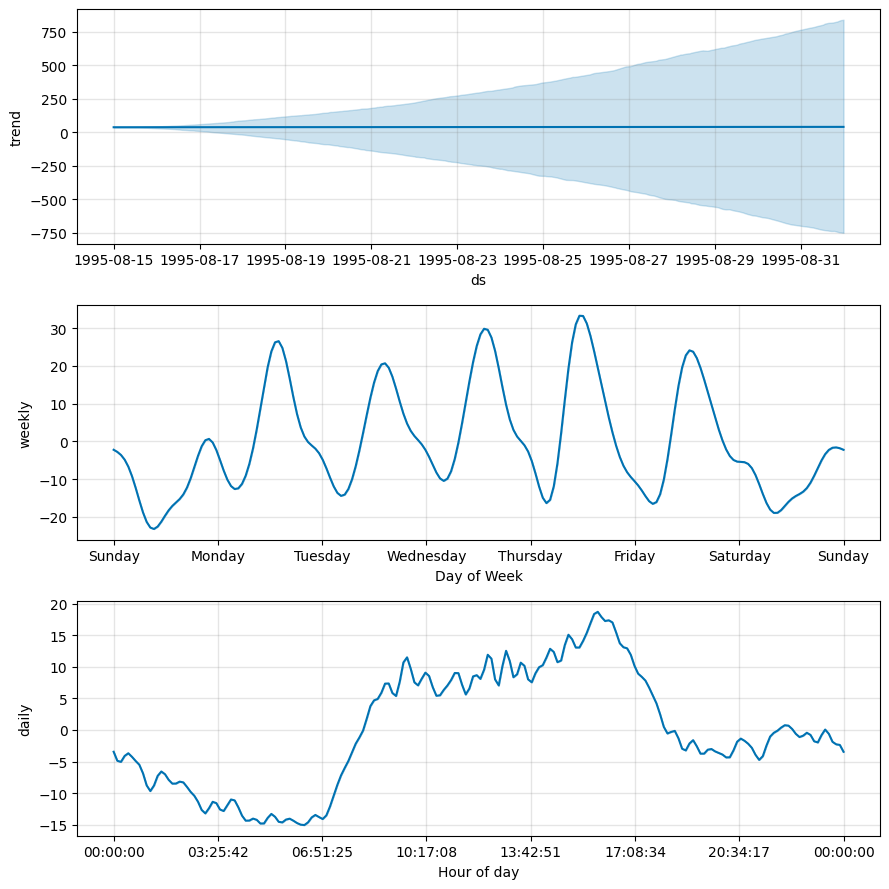

In [14]:
components_fig = model_one.plot_components(forecast_test_df_nasa)
ax_weekly = components_fig.get_axes()[1]
ax_daily = components_fig.get_axes()[2]

plt.figure(figsize=(14, 5))
plt.plot(ax_weekly.lines[0].get_xdata(), ax_weekly.lines[0].get_ydata())
plt.title('NASA Seasonality Weekly Component')
plt.xlabel(ax_weekly.get_xlabel())
plt.ylabel(ax_weekly.get_ylabel())
plt.grid(True)
plt.savefig("images/nasa-prophet-weekly.jpeg", dpi=300, bbox_inches='tight', pad_inches=0)
plt.close()


plt.figure(figsize=(14, 5))
plt.plot(ax_daily.lines[0].get_xdata(), ax_daily.lines[0].get_ydata())
plt.title('NASA Seasonality Daily Component')
plt.xlabel(ax_daily.get_xlabel())
plt.ylabel(ax_daily.get_ylabel())
plt.grid(True)
plt.savefig("images/nasa-prophet-daily.jpeg", dpi=300, bbox_inches='tight', pad_inches=0)
plt.close()

## Merge Forecasted Data

In [15]:
forecast_df_nasa = pd.concat([forecast_train_df_nasa, forecast_test_df_nasa])

## Residual Analysis

### Calculate Residuals

In [16]:
df_nasa_residual = df_nasa.merge(forecast_df_nasa[['ds', 'yhat']], on='ds', how='left')
df_nasa_residual['residual'] = df_nasa_residual['y'] - df_nasa_residual['yhat']
df_nasa_residual.head()

,ds,y,yhat,residual
0,1995-07-01 00:00:00,42,48.529996,-6.529996
1,1995-07-01 00:01:00,61,48.308559,12.691441
2,1995-07-01 00:02:00,57,48.083695,8.916305
3,1995-07-01 00:03:00,71,47.860993,23.139007
4,1995-07-01 00:04:00,70,47.646132,22.353868


### Prepare Dataset for LSTM

In [17]:
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_df_nasa = scaler.fit_transform(df_nasa_residual[['residual']])

In [18]:
def create_dataset(dataset, look_back):
    X, y = [], []
    for i in range(len(dataset) - look_back):
        a = dataset[i:(i + look_back), 0]
        X.append(a)
        y.append(dataset[i + look_back, 0])
    return np.array(X), np.array(y)

In [19]:
look_back = 1
X_nasa, y_nasa = create_dataset(scaled_df_nasa, look_back)

In [20]:
X_train_nasa, X_test_nasa, y_train_nasa, y_test_nasa = train_test_split(X_nasa, y_nasa, test_size=0.3, random_state=42, shuffle=False)

X_train_nasa = np.reshape(X_train_nasa, (X_train_nasa.shape[0], X_train_nasa.shape[1], 1))
X_test_nasa = np.reshape(X_test_nasa, (X_test_nasa.shape[0], X_test_nasa.shape[1], 1))

print(f'NASA DATASET: Train Set: {X_train_nasa.shape} | Test Set: {X_test_nasa.shape}')

NASA DATASET: Train Set: (56976, 1, 1) | Test Set: (24419, 1, 1)


### Model Definition

In [21]:
model_two = None

#### Early Stopping

In [22]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

#### HyperParameter Tuning (If Enabled)

In [23]:
def build_model(hp):
    model = Sequential()
    model.add(LSTM(units=hp.Int('units', min_value=32, max_value=512, step=32), return_sequences=True, input_shape=(look_back, 1)))
    model.add(LSTM(units=hp.Int('units', min_value=32, max_value=512, step=32), return_sequences=False))
    model.add(Dense(1))
    
    model.compile(optimizer=hp.Choice('optimizer', values=['adam', 'rmsprop']), loss='mean_squared_error')
    return model

In [24]:
tuner = kt.RandomSearch(
    build_model,
    objective='val_loss',
    max_trials=10,
    executions_per_trial=2,
    directory='hyperparam_tuning',
    project_name='lstm_hyperparam_tuning'
)

C:\Users\sofia\.codex\.chatgpt-projects\g-p-67a332acf1fc8191bddbeac79c7b1526\research-reproduction\environments\forecast-venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [25]:
if HYPERPARAMETER_TUNING:
    tuner.search(X_train_nasa, y_train_nasa, epochs=50, batch_size=16, validation_split=0.2, callbacks=[early_stopping], verbose=1)

In [26]:
if HYPERPARAMETER_TUNING:
    model_two = tuner.get_best_models(num_models=1)[0]
    model_two_hyperparameters = tuner.get_best_hyperparameters(num_trials=1)[0]
    print(f"Units: {model_two_hyperparameters.get('units')}")
    print(f"Optimizer: {model_two_hyperparameters.get('optimizer')}")

#### Default Model

In [27]:
if not HYPERPARAMETER_TUNING:
    model_two = Sequential()
    model_two.add(LSTM(50, return_sequences=True, input_shape=(look_back, 1)))
    model_two.add(LSTM(50, return_sequences=False))
    model_two.add(Dense(1))
    model_two.compile(optimizer='adam', loss='mean_squared_error')

Print Model Summery

In [28]:
model_two.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 1, 50)          │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

### Train Model

In [29]:
model_two.fit(X_train_nasa, y_train_nasa, epochs=20, batch_size=16, validation_split=0.2, callbacks=[early_stopping], verbose=1)

Epoch 1/20


   1/2849 ━━━━━━━━━━━━━━━━━━━━ 1:33:25 2s/step - loss: 0.0917

  40/2849 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 0.0642    

  80/2849 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 0.0473

 119/2849 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 0.0379

 151/2849 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 0.0329

... (462 outputs left out)

2737/2849 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0015

2778/2849 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0015

2822/2849 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0015

2849/2849 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.0015 - val_loss: 0.0013


### Predict Dataset

In [30]:
nasa_train_predict = model_two.predict(X_train_nasa)
nasa_train_predict = scaler.inverse_transform(nasa_train_predict)
y_train_nasa_org = scaler.inverse_transform([y_train_nasa])

start_time = time.time()
nasa_test_predict = model_two.predict(X_test_nasa)
end_time = time.time()
nasa_test_predict = scaler.inverse_transform(nasa_test_predict)
y_test_nasa_org = scaler.inverse_transform([y_test_nasa])

print(f'NASA DATASET - Prediction Size Train: {len(nasa_train_predict)} | Prediction Size Test: {len(nasa_test_predict)}')

   1/1781 ━━━━━━━━━━━━━━━━━━━━ 5:52 198ms/step

  63/1781 ━━━━━━━━━━━━━━━━━━━━ 1s 809us/step  

 132/1781 ━━━━━━━━━━━━━━━━━━━━ 1s 777us/step

 199/1781 ━━━━━━━━━━━━━━━━━━━━ 1s 771us/step

 270/1781 ━━━━━━━━━━━━━━━━━━━━ 1s 755us/step

 339/1781 ━━━━━━━━━━━━━━━━━━━━ 1s 750us/step

... (33 outputs left out)

655/764 ━━━━━━━━━━━━━━━━━━━━ 0s 699us/step

725/764 ━━━━━━━━━━━━━━━━━━━━ 0s 701us/step

764/764 ━━━━━━━━━━━━━━━━━━━━ 1s 703us/step


NASA DATASET - Prediction Size Train: 56976 | Prediction Size Test: 24419


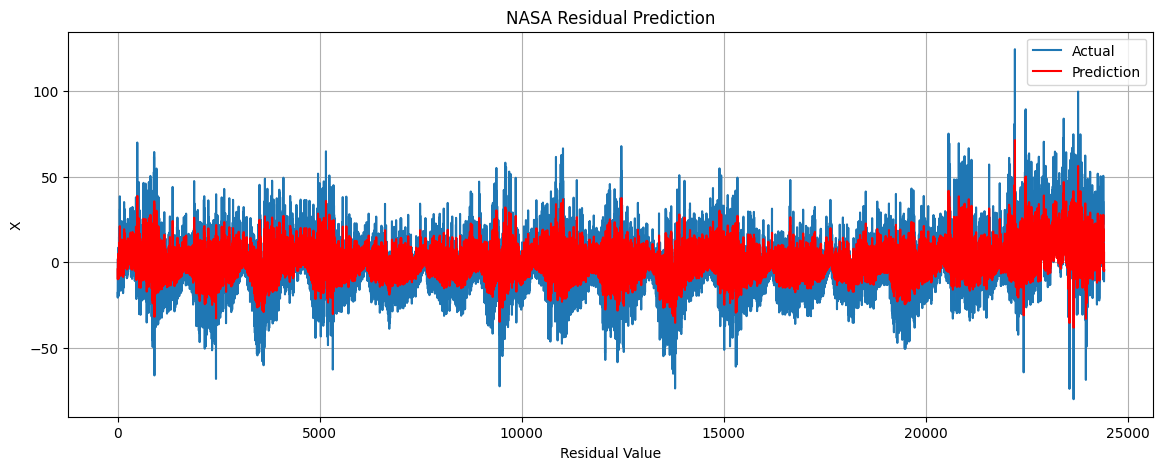

In [31]:
plt.figure(figsize=(14,5))
plt.plot(y_test_nasa_org[0], label='Actual', color='#1f77b4')
plt.plot(nasa_test_predict, label='Prediction', color='red')
plt.xlabel('Residual Value')
plt.ylabel('X')
plt.title('NASA Residual Prediction')
plt.legend()
plt.grid(True)
plt.savefig("images/nasa-lstm-output.jpeg", dpi=300, bbox_inches='tight', pad_inches=0)
plt.show()

In [32]:
mse = mean_squared_error(y_test_nasa_org[0], nasa_test_predict)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_nasa_org[0], nasa_test_predict)
r2 = r2_score(y_test_nasa_org[0], nasa_test_predict)
model_two_time = (end_time - start_time) * 1000

print('=== LSTM Residual Analysis Model Metrics ===')
print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'MAE: {mae}')
print(f'R2: {r2}')
print(f'Prediction Time: {model_two_time}ms')

=== LSTM Residual Analysis Model Metrics ===
MSE: 203.76714391786822
RMSE: 14.274702936238926
MAE: 10.8799649135142
R2: 0.23253856802474382
Prediction Time: 757.6453685760498ms


## Combine Results from Both Models

In [33]:
nasa_combine_predict = np.concatenate((nasa_train_predict, nasa_test_predict))

final_df_nasa = df_nasa_residual.copy()

final_df_nasa['residual_predict'] = np.nan
final_df_nasa['residual_predict'].iloc[0:len(nasa_combine_predict)] = nasa_combine_predict[:, 0]
print(f'NASA DATASET: Total Output: {final_df_nasa.shape[0]} | Loss: {final_df_nasa['residual_predict'].isna().sum()}')

final_df_nasa['residual_predict'] = final_df_nasa['residual_predict'].fillna(final_df_nasa['residual'])

final_df_nasa['y_predicted'] = final_df_nasa['yhat'] + final_df_nasa['residual_predict']

final_df_nasa.head()

NASA DATASET: Total Output: 81396 | Loss: 1


C:\Users\sofia\AppData\Local\Temp\ipykernel_10552\867113017.py:6: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  final_df_nasa['residual_predict'].iloc[0:len(nasa_combine_predict)] = nasa_combine_predict[:, 0]
C:\Users\sofia\AppData\Local\Tem

,ds,y,yhat,residual,residual_predict,y_predicted
0,1995-07-01 00:00:00,42,48.529996,-6.529996,-2.787679,45.742318
1,1995-07-01 00:01:00,61,48.308559,12.691441,7.196486,55.505045
2,1995-07-01 00:02:00,57,48.083695,8.916305,5.211763,53.295458
3,1995-07-01 00:03:00,71,47.860993,23.139007,12.750264,60.611257
4,1995-07-01 00:04:00,70,47.646132,22.353868,12.329784,59.975916


### Extract Test Dataset Related Dataframe & Calculate Metrics

In [34]:
final_df_nasa_analysis = final_df_nasa.iloc[train_df_nasa.shape[0]:]
final_df_nasa_analysis.tail()

print(f'NASA DATASET: Testing Output: {final_df_nasa_analysis.shape}')

NASA DATASET: Testing Output: (24419, 6)


In [35]:
mse = mean_squared_error(final_df_nasa_analysis['y'], final_df_nasa_analysis['y_predicted'])
rmse = np.sqrt(mse)
mae = mean_absolute_error(final_df_nasa_analysis['y'], final_df_nasa_analysis['y_predicted'])
r2 = r2_score(final_df_nasa_analysis['y'], final_df_nasa_analysis['y_predicted'])

print('=== Hybrid Model Metrics ===')
print(f'MSE: {mse:.3f}')
print(f'RMSE: {rmse:.3f}')
print(f'MAE: {mae:.3f}')
print(f'R²: {r2:.3f}')
print(f'Prediction Time: {model_one_time + model_two_time}ms')

=== Hybrid Model Metrics ===
MSE: 64.194
RMSE: 8.012
MAE: 6.191
R²: 0.900
Prediction Time: 5043.768405914307ms


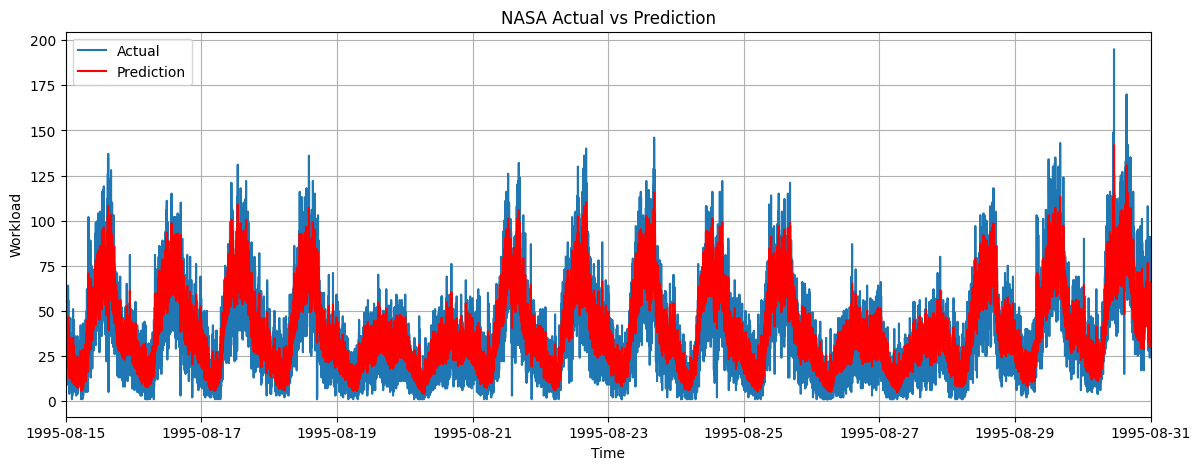

In [36]:
plt.figure(figsize=(14, 5))
# plt.plot(train_df_nasa['ds'], train_df_nasa['y'], label='Train', color='green')
plt.plot(test_df_nasa['ds'], test_df_nasa['y'], label='Actual', color='#1f77b4')
plt.plot(final_df_nasa_analysis['ds'], final_df_nasa_analysis['y_predicted'], label='Prediction', color='red')
plt.xlim(pd.to_datetime('1995-08-15'), pd.to_datetime('1995-08-31'))
plt.title('NASA Actual vs Prediction')
plt.xlabel('Time')
plt.ylabel('Workload')
plt.grid(True)
plt.legend()
plt.savefig("images/nasa-final-output.jpeg", dpi=300, bbox_inches='tight', pad_inches=0)
plt.show()

## Save Models

In [37]:
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

filename = f'models/fbprophet-nasa-{timestamp}.json'
with open(filename, 'w') as fout:
    fout.write(model_to_json(model_one))

filename = f'models/lstm-nasa-{timestamp}.keras' 
model_two.save(filename)

## Reproduction artifact export
Added instrumentation below exports existing state. All preceding author cells are unchanged; no evaluation corrections are applied.

In [38]:

# Reproduction instrumentation: export existing notebook state without retraining.
import json as _json
from pathlib import Path as _Path
import platform as _platform
import importlib.metadata as _metadata
_out = _Path('C:\\Users\\sofia\\.codex\\.chatgpt-projects\\g-p-67a332acf1fc8191bddbeac79c7b1526\\research-reproduction\\results\\nasa\\run-01')
_out.mkdir(parents=True, exist_ok=True)
_df = final_df_nasa.copy()
_df['partition'] = np.where(np.arange(len(_df)) < len(train_df_nasa), 'train', 'test')
_df['row_index'] = np.arange(len(_df))
_df.to_csv(_out / 'predictions.csv', index=False, float_format='%.17g')
_test = final_df_nasa_analysis
_history = model_two.history.history
_metrics = {
    'dataset': 'nasa', 'run_id': 'run-01',
    'method': 'authors_released_alignment_and_preprocessing',
    'MSE': float(mean_squared_error(_test['y'], _test['y_predicted'])),
    'RMSE': float(np.sqrt(mean_squared_error(_test['y'], _test['y_predicted']))),
    'MAE': float(mean_absolute_error(_test['y'], _test['y_predicted'])),
    'R2': float(r2_score(_test['y'], _test['y_predicted'])),
    'TPT_ms': float(model_one_time + model_two_time),
    'prophet_prediction_ms': float(model_one_time),
    'lstm_prediction_ms': float(model_two_time),
    'epochs_completed': len(_history['loss']),
    'best_validation_epoch': int(np.argmin(_history['val_loss']) + 1),
    'history': {k: [float(v) for v in values] for k, values in _history.items()},
    'n_rows': len(_df), 'n_train_prophet': len(train_df_nasa),
    'n_test_scored': len(_test), 'n_train_lstm': len(X_train_nasa),
    'n_test_lstm': len(X_test_nasa), 'look_back': look_back,
    'growth': model_one.growth,
    'scaler': {'min': scaler.data_min_.tolist(), 'max': scaler.data_max_.tolist()},
    'versions': {p: _metadata.version(p) for p in ['tensorflow','keras','prophet','numpy','pandas','scikit-learn','keras-tuner','cmdstanpy']},
    'python': _platform.python_version(),
    'tensorflow_devices': [str(x) for x in tf.config.list_physical_devices()],
    'author_numpy_seed': 42, 'author_tensorflow_seed': 42,
    'python_random_seed': 'not explicitly set by author notebook',
    'final_row_truth_fallback': bool(np.isclose(_df['y'].iloc[-1], _df['y_predicted'].iloc[-1])),
}
(_out / 'metrics.json').write_text(_json.dumps(_metrics, indent=2), encoding='utf-8')
pd.DataFrame(_metrics['history']).assign(epoch=lambda x: np.arange(1, len(x)+1)).to_csv(_out / 'training-history.csv', index=False)
forecast_test_df_nasa.to_csv(_out / 'prophet-test-predictions.csv', index=False, float_format='%.17g')
np.savez_compressed(_out / 'residual-predictions.npz', train=nasa_train_predict, test=nasa_test_predict, targets=y_test_nasa)
print('REPRODUCTION_EXPORT', _json.dumps({k: _metrics[k] for k in ['MSE','RMSE','MAE','R2','TPT_ms','epochs_completed']}))


KeyError: 'loss'